In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare

In [3]:
STRATEGIES = {
    "BuyHold": {"classic_dca": True},
    "Default": {},
    "Experimental1": {"cooldown_long": 90},
    "NoConfirm": {"manual_sell_fraction": 0.5, "minimum_profit": 2.0},
    "Experimental2": {"cooldown_long": 90, "manual_sell_fraction": 0.5, "minimum_profit": 2.0},
}

In [4]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_prices.drop("DOGE", axis=1, inplace=True)
df_prices

,BTC,ETH,SOL,XRP,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.212025,1.111869,11.943166,0.175209,600.638428


# COMPARE

In [5]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 5/5 [04:17<00:00, 51.51s/it]


In [6]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MA200_survival_days,RoAC,iteration
0,BuyHold,ETH,2059,0,5326,2059,5326,98,1124.857377,0,-4317,16.000000,180,1
1,BuyHold,DOT,2059,0,778,2059,778,16,5.634832,0,-1799,131.250000,-23,1
2,BuyHold,XLM,2069,0,2308,2069,2308,69,0.108260,0,-6450,93.000000,96,1
3,BuyHold,XRP,2059,0,3480,2059,3480,43,0.361745,0,-6569,50.333333,42,1
4,BuyHold,XRP,2069,0,1995,2069,1995,57,0.356536,0,-6293,144.750000,58,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,Experimental2,LINK,2168,3731,496,871,4227,76,10.861003,12,-560,62.142857,646,100
4996,Experimental2,DOT,2405,0,852,2405,852,21,3.481238,6,-1858,0.000000,-16,100
4997,Experimental2,XRP,2207,3803,323,546,4127,45,0.526901,7,-1731,32.000000,237,100
4998,Experimental2,BTC,2069,4336,408,570,4745,76,29870.840871,6,-664,0.000000,442,100


In [7]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_median=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res['Uncle'] = compare_res['MDD'] / compare_res['Total_value_mean']
compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_median,Total_value_low,Total_value_high,Uncle
strategy,,,,,,,,,,
Experimental2,311.67,-1151.89,1050.37,3448.22,2164.99,4499.07,4228.50,3305.50,5277.75,-0.26
NoConfirm,296.31,-781.33,901.65,3013.95,2187.68,3916.07,3908.50,3199.25,4730.75,-0.20
Default,262.61,-555.97,823.54,2929.63,2184.20,3753.67,3641.00,3045.75,4352.00,-0.15
Experimental1,241.52,-1511.06,1455.59,3073.75,2169.22,4529.83,3719.00,2994.25,5105.00,-0.33
BuyHold,170.26,-10392.78,6092.23,0.00,2064.74,6092.23,3525.50,2172.50,6691.00,-1.71


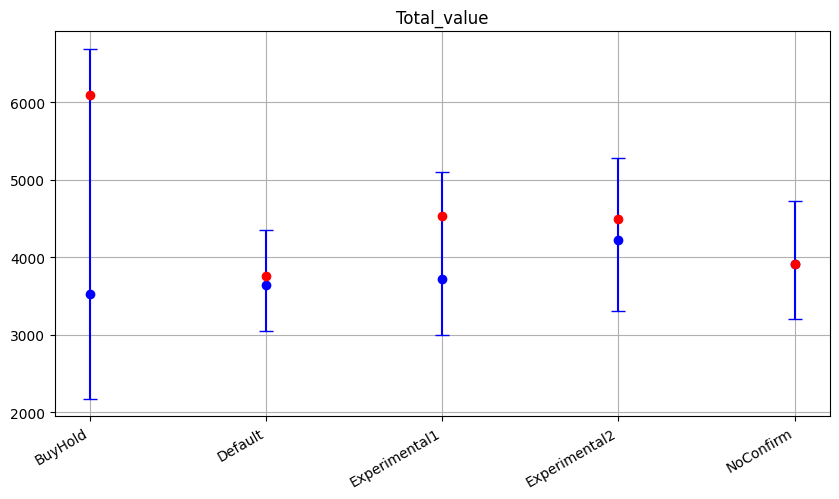

In [8]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

median = compare_res[f"{metric}_median"]
mean = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    median.index,
    median.values,
    yerr=[median - low, high - median],
    fmt="o",
    capsize=5,
    label="median",
    color="blue",
)
plt.errorbar(
    mean.index,
    mean.values,
    fmt="o",
    capsize=5,
    label="mean",
    color="red",
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()